# **실습 개요**

여러분은 스마트 팩토리의 **설비 예지보전(Predictive Maintenance)** 팀에 합류한 데이터 분석가입니다. <br>
공장의 회전 설비(모터/펌프)에는 진동, 온도, 전류/전압, 압력 등을 측정하는 센서 25개가 부착되어 있고, <br>
이 센서 데이터를 바탕으로 설비 상태(정상 / 주의 / 고장)를 미리 예측해 고장 전에 정비 계획을 세우려고 합니다.

다만 센서 수가 많고, 물리적으로 서로 얽혀 있는 센서들(예: 진동을 측정하는 여러 센서, 온도를 측정하는 여러 센서)이 <br>
강한 상관관계(다중공선성)를 갖고 있어 어떻게 전처리하느냐에 따라 모델 성능이 크게 달라집니다.

## **데이터셋 설명**

설비 1,000대(대수가 아니라 측정 시점 기준)에서 수집한 센서 데이터와 실제 설비 상태(정답)를 담은 데이터입니다.

| 컬럼명 | 설명 |
|---|---|
| vibration_x / vibration_y / vibration_z / vibration_axial | 진동 센서 (X/Y/Z축, 축방향, mm/s) |
| noise_level | 설비 소음 레벨 (dB) |
| temp_bearing_1 / temp_bearing_2 | 베어링 온도 (℃) |
| temp_motor | 모터 온도 (℃) |
| temp_gearbox | 기어박스 온도 (℃) |
| temp_housing | 하우징 온도 (℃) |
| current_phase_a / current_phase_b / current_phase_c | 3상 전류 (A) |
| voltage_a / voltage_b / voltage_c | 3상 전압 (V) |
| pressure_inlet / pressure_outlet / pressure_mid | 유입 / 유출 / 중간 압력 (bar) |
| rotation_speed | 회전 속도 (RPM) |
| humidity | 설비 주변 습도 (%) |
| operating_hours | 누적 가동 시간 (시간) |
| oil_quality_index | 윤활유 품질 지수 (0~100, 높을수록 양호) |
| equipment_age_years | 설비 사용 연수 (년) |
| outdoor_installed | 실외 설치 여부 (Yes/No) |
| status | **[target]** 설비 상태 (Normal / Warning / Failure) |

## **데이터셋 URL**
https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/machine_status.csv

## **1. 데이터 살펴보기**

**Q1. 데이터를 불러오고, 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.**

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/machine_status.csv")
df.head()

,vibration_x,vibration_y,vibration_z,vibration_axial,noise_level,temp_bearing_1,temp_bearing_2,temp_motor,temp_gearbox,temp_housing,...,pressure_inlet,pressure_outlet,pressure_mid,rotation_speed,humidity,operating_hours,oil_quality_index,equipment_age_years,outdoor_installed,status
0,7.123,6.652,6.929,6.496,7.026,70.01,63.38,67.00,60.78,64.56,...,4.734,4.480,4.674,1385.0,59.8,3019.8,90.45,13.98,Yes,Warning
1,5.896,5.402,5.410,5.547,5.955,69.37,63.55,67.57,68.94,67.28,...,4.606,4.282,4.404,1570.6,50.0,2210.2,72.00,0.58,No,Warning
2,5.467,4.831,4.879,5.387,5.392,77.81,72.99,73.75,68.76,73.36,...,4.709,4.470,4.885,1445.5,50.0,5447.8,96.38,10.47,Yes,Normal
3,4.963,5.303,5.796,5.451,4.637,77.10,72.35,70.66,75.30,76.93,...,4.932,4.641,4.718,1719.3,62.1,5209.7,80.67,12.65,No,Warning
4,5.469,5.368,5.637,5.929,5.157,71.02,75.60,73.67,78.90,71.75,...,4.677,4.461,4.266,1502.8,47.2,4959.9,87.11,10.76,No,Normal


**Q2. 데이터의 크기와 컬럼별 정보를 확인합니다.**

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1022 entries, 0 to 1021
Data columns (total 26 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   vibration_x          1022 non-null   float64
 1   vibration_y          1022 non-null   float64
 2   vibration_z          1022 non-null   float64
 3   vibration_axial      1022 non-null   float64
 4   noise_level          1022 non-null   float64
 5   temp_bearing_1       1022 non-null   float64
 6   temp_bearing_2       982 non-null    float64
 7   temp_motor           1022 non-null   float64
 8   temp_gearbox         1022 non-null   float64
 9   temp_housing         1022 non-null   float64
 10  current_phase_a      1022 non-null   float64
 11  current_phase_b      992 non-null    float64
 12  current_phase_c      1022 non-null   float64
 13  voltage_a            1022 non-null   float64
 14  voltage_b            1022 non-null   float64
 15  voltage_c            1022 non-null   float64
 16 

**Q3. 수치형 컬럼들의 기술 통계량을 확인합니다.**

In [5]:
df.describe()

,vibration_x,vibration_y,vibration_z,vibration_axial,noise_level,temp_bearing_1,temp_bearing_2,temp_motor,temp_gearbox,temp_housing,...,voltage_b,voltage_c,pressure_inlet,pressure_outlet,pressure_mid,rotation_speed,humidity,operating_hours,oil_quality_index,equipment_age_years
count,1022.000000,1022.000000,1022.000000,1022.000000,1022.000000,1022.000000,982.000000,1022.000000,1022.000000,1022.000000,...,1022.000000,1022.000000,1022.000000,1022.000000,1022.000000,1022.000000,970.000000,1022.000000,996.000000,1022.000000
mean,6.473698,6.480381,7.091297,6.444840,6.492987,67.644599,67.628289,67.445910,67.665264,67.536145,...,21.961586,22.036116,4.600812,4.590687,4.603582,1477.069374,45.285979,3683.757436,84.775954,7.754961
std,1.015323,1.027228,4.750587,1.001625,1.034642,4.944803,4.991179,4.826289,4.783194,4.851461,...,9.823294,1.336552,0.303574,0.298983,0.305891,121.874571,10.366099,2811.911009,11.632900,4.198373
min,3.924000,3.814000,3.962000,3.861000,3.587000,53.450000,54.290000,55.410000,54.530000,54.550000,...,-78.078216,18.863000,3.620000,3.635000,3.703000,1086.000000,16.000000,161.100000,50.640000,0.500000
25%,5.696500,5.712000,5.712000,5.691500,5.739250,63.682500,63.845000,63.712500,64.042500,63.675000,...,20.962500,20.997250,4.384250,4.372250,4.382250,1397.250000,38.525000,1600.725000,76.212500,4.092500
50%,6.477500,6.486000,6.478000,6.470000,6.477500,67.720000,67.590000,67.480000,67.650000,67.500000,...,22.108500,22.033000,4.601500,4.586500,4.595000,1471.550000,45.300000,2860.550000,84.155000,7.825000
75%,7.259000,7.213500,7.296750,7.152250,7.282500,71.560000,71.522500,71.275000,71.225000,71.307500,...,23.102250,23.126750,4.813750,4.814250,4.821500,1566.550000,52.600000,5043.600000,93.147500,11.347500
max,9.248000,9.668000,49.943996,9.553000,9.121000,79.430000,82.130000,79.610000,80.280000,78.370000,...,120.922740,25.209000,5.466000,5.377000,5.587000,1913.100000,80.100000,22678.500000,117.020000,14.980000


## **2. 데이터 전처리하기**

### **2-1. 중복 데이터 제거하기**

**Q1. 중복된 행이 몇 개 있는지 확인하세요.**

In [6]:
df.duplicated().sum()

np.int64(22)

**Q2. 중복된 행을 제거하세요.**

In [7]:
df = df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

### **2-2. 데이터 분리하기**

**Q1. status를 target으로 하여 train과 test 데이터를 분리하세요.**
- 비율: 7(학습):3(테스트)
- random_state = 101
- status 클래스 비율이 불균형하므로 stratify 옵션을 사용합니다.

In [8]:
from sklearn.model_selection import train_test_split

df.head(2)

X = df.drop(columns='status')
y = df['status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=101, stratify=y
)


### **2-3. 결측치 처리하기**

**Q1. train 데이터의 컬럼별 결측치 개수를 확인하세요.**

In [9]:
X_train.isnull().sum()

vibration_x             0
vibration_y             0
vibration_z             0
vibration_axial         0
noise_level             0
temp_bearing_1          0
temp_bearing_2         23
temp_motor              0
temp_gearbox            0
temp_housing            0
current_phase_a         0
current_phase_b        26
current_phase_c         0
voltage_a               0
voltage_b               0
voltage_c               0
pressure_inlet          0
pressure_outlet         0
pressure_mid            0
rotation_speed          0
humidity               36
operating_hours         0
oil_quality_index      16
equipment_age_years     0
outdoor_installed      13
dtype: int64

**Q2. 결측치가 존재하는 행들의 type을 확인하세요.**

In [10]:
# missing_rows = X_train[X_train.isnull().any(axis=1)]

# display(missing_rows)
# display(missing_rows.dtypes)

missing_cols = X_train.columns[X_train.isnull().any()]

display(X_train[missing_cols].dtypes)

temp_bearing_2       float64
current_phase_b      float64
humidity             float64
oil_quality_index    float64
outdoor_installed        str
dtype: object

**Q3. 수치형 컬럼의 결측치들을 중앙값(median)으로 대체합니다.**

반드시 train 데이터의 통계량으로 test 데이터도 함께 처리해야 데이터 누수(data leakage)를 방지할 수 있습니다.

In [11]:
from sklearn.impute import SimpleImputer

num_cols = X_train.select_dtypes(include='number').columns

imputer = SimpleImputer(strategy='median')

X_train[num_cols] = imputer.fit_transform(X_train[num_cols])
X_test[num_cols] = imputer.transform(X_test[num_cols])

**Q3. 범주형 컬럼의 결측치를 train 데이터의 최빈값(mode)으로 대체하세요.**

In [12]:
from sklearn.impute import SimpleImputer

cat_cols = X_train.select_dtypes(
    include = ['object', 'category', 'string']
).columns

cat_imputer = SimpleImputer(strategy="most_frequent")

X_train[cat_cols] = cat_imputer.fit_transform(X_train[cat_cols])
X_test[cat_cols] = cat_imputer.fit_transform(X_test[cat_cols])


### **2-4. 이상치 처리하기**

**Q1. IQR을 활용하여 각 수치형 컬럼에 이상치가 몇 개씩 있는지 확인하는 함수를 작성하세요.**

In [13]:
def count_outliers(df):
    num_cols = df.select_dtypes(include='number').columns

    q1 = df[num_cols].quantile(0.25)
    q3 = df[num_cols].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - iqr * 1.5
    upper = q3 + iqr * 1.5

    count = ((df[num_cols] < lower) | (df[num_cols] > upper)).sum()

    print(f'{num_cols}: {count}개')


count_outliers(X_train)


Index(['vibration_x', 'vibration_y', 'vibration_z', 'vibration_axial',
       'noise_level', 'temp_bearing_1', 'temp_bearing_2', 'temp_motor',
       'temp_gearbox', 'temp_housing', 'current_phase_a', 'current_phase_b',
       'current_phase_c', 'voltage_a', 'voltage_b', 'voltage_c',
       'pressure_inlet', 'pressure_outlet', 'pressure_mid', 'rotation_speed',
       'humidity', 'operating_hours', 'oil_quality_index',
       'equipment_age_years'],
      dtype='str'): vibration_x             0
vibration_y             1
vibration_z            16
vibration_axial         0
noise_level             0
temp_bearing_1          0
temp_bearing_2          0
temp_motor              0
temp_gearbox            0
temp_housing            0
current_phase_a         0
current_phase_b         0
current_phase_c         0
voltage_a               0
voltage_b              11
voltage_c               0
pressure_inlet          3
pressure_outlet         1
pressure_mid            2
rotation_speed          5
humidit

**Q2. 이상치에 해당하는 값들을 모두 clipping 해주세요.**


In [17]:
num_cols = X_train.select_dtypes(include="number").columns
num_cols.to_frame()

,0
vibration_x,vibration_x
vibration_y,vibration_y
vibration_z,vibration_z
vibration_axial,vibration_axial
noise_level,noise_level
temp_bearing_1,temp_bearing_1
temp_bearing_2,temp_bearing_2
temp_motor,temp_motor
temp_gearbox,temp_gearbox
temp_housing,temp_housing


In [ ]:
m_cols = X_train.select_dtypes(include="number").columns

q1 = X_train[num_cols].quantile(0.25)
q3 = X_train[num_cols].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

X_train[num_cols] = X_train[num_cols].clip(lower=lower, upper=upper, axis=1)
X_test[num_cols] = X_test[num_cols].clip(lower=lower, upper=upper, axis=1)


count_outliers(X_train)

Index(['vibration_x', 'vibration_y', 'vibration_z', 'vibration_axial',
       'noise_level', 'temp_bearing_1', 'temp_bearing_2', 'temp_motor',
       'temp_gearbox', 'temp_housing', 'current_phase_a', 'current_phase_b',
       'current_phase_c', 'voltage_a', 'voltage_b', 'voltage_c',
       'pressure_inlet', 'pressure_outlet', 'pressure_mid', 'rotation_speed',
       'humidity', 'operating_hours', 'oil_quality_index',
       'equipment_age_years'],
      dtype='str'): vibration_x            0
vibration_y            0
vibration_z            0
vibration_axial        0
noise_level            0
temp_bearing_1         0
temp_bearing_2         0
temp_motor             0
temp_gearbox           0
temp_housing           0
current_phase_a        0
current_phase_b        0
current_phase_c        0
voltage_a              0
voltage_b              0
voltage_c              0
pressure_inlet         0
pressure_outlet        0
pressure_mid           0
rotation_speed         0
humidity               0
op

### **2-5. Feature Encoding**

**Q1. outdoor_installed 컬럼을 label 인코딩하세요.**

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()


X_train['outdoor_installed'] = le.fit_transform(X_train['outdoor_installed'])
X_test['outdoor_installed'] = le.transform(X_test['outdoor_installed'])


### **2-6. 다중공선성 확인하기**

**Q1. train 데이터(수치형 컬럼)의 상관행렬을 시각화하세요.**

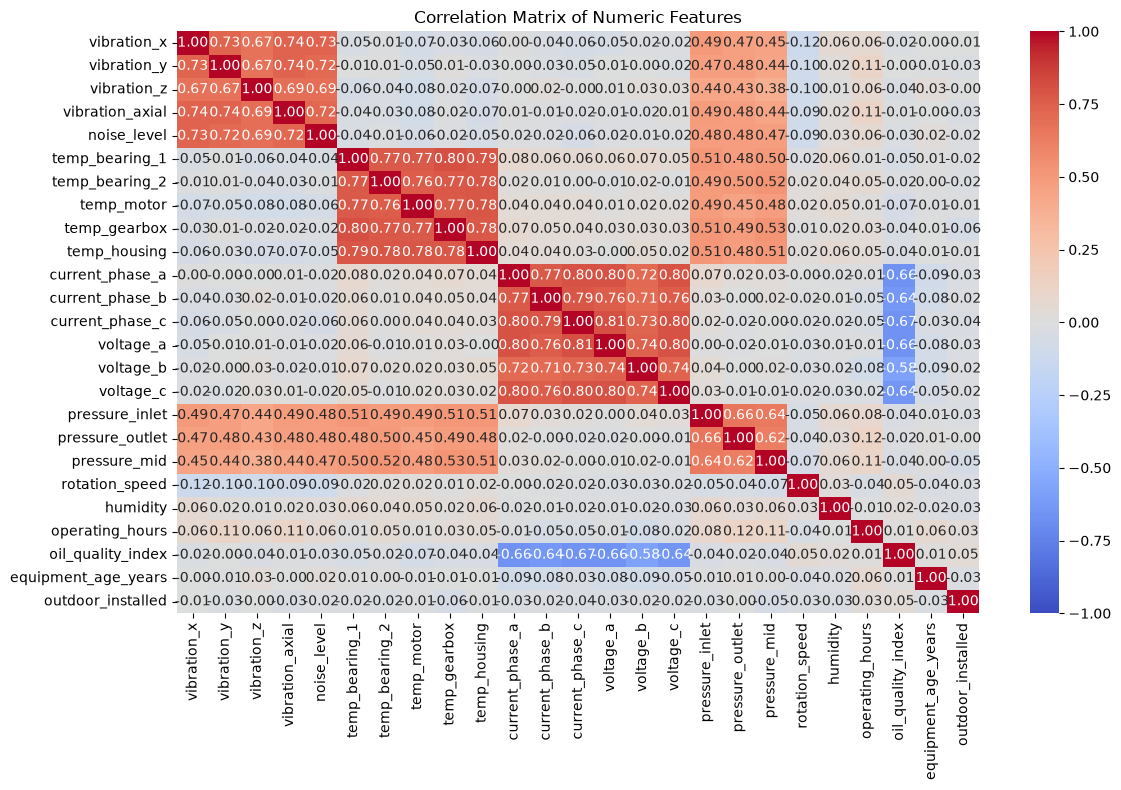

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

num_train = X_train.select_dtypes(include="number")

# 상관행렬 계산 : .corr()
corr = num_train.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Matrix of Numeric Features")
plt.tight_layout()
plt.show()


### **2-7. Feature Scaling**

**Q1. StandardScaler를 사용하여 feature scaling을 진행하세요.**

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# 결과는 NumPy 배열
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 기존 컬럼명을 유지하려면 DataFrame으로 감싸세요
X_train_scaled = pd.DataFrame(
    X_train_scaled, columns=X_train.columns, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    X_test_scaled, columns=X_test.columns, index=X_test.index
)

X_test_scaled

,vibration_x,vibration_y,vibration_z,vibration_axial,noise_level,temp_bearing_1,temp_bearing_2,temp_motor,temp_gearbox,temp_housing,...,voltage_c,pressure_inlet,pressure_outlet,pressure_mid,rotation_speed,humidity,operating_hours,oil_quality_index,equipment_age_years,outdoor_installed
227,-0.070265,0.050928,-0.480341,-1.225406,-0.160207,-0.312924,-1.174758,-0.234474,-0.796893,-0.078975,...,-0.159411,-1.253872,-1.070929,-1.877257,-0.329413,-0.039606,-0.105110,-0.384827,1.126216,-0.663573
378,-0.317432,-0.642307,-0.784132,0.083938,-0.632338,-0.266687,-0.119040,-0.931450,-0.239253,-0.535978,...,-0.759961,-0.216523,-0.628584,-1.456586,0.921583,0.531765,-0.993631,0.337441,0.928883,-0.663573
231,-0.069276,-1.062074,-0.161920,-0.041278,-0.801846,-0.075706,0.482761,0.205832,0.450347,0.469845,...,-1.021719,-0.216523,-0.142004,0.308907,2.506067,0.199331,-0.434788,1.754672,0.458138,1.506993
302,-0.201758,-0.600235,-0.190320,-0.436644,0.349273,-1.716131,-1.092601,-1.221509,-0.662804,-1.105667,...,0.171153,-1.306230,-1.268283,-1.168410,-1.491696,-1.410898,2.506629,-1.147613,0.163328,-0.663573
935,-1.168678,-1.244705,-0.797901,-1.147516,-0.664899,0.595743,1.100993,0.742128,0.692984,0.749473,...,-0.654509,-0.458680,0.130208,0.872010,-0.648117,0.043502,0.683931,2.808457,-0.752010,-0.663573
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
321,-0.214611,-0.686292,-0.276379,-0.180297,-0.916766,-0.626535,-0.188873,-0.860500,0.294974,-0.550586,...,1.540525,-1.014987,-0.798717,0.040605,1.378282,0.448657,-0.837494,-1.245384,-0.747255,-0.663573
339,-1.576999,-0.484537,-0.648157,-0.312414,-1.223220,-1.046693,-0.513394,-1.530349,0.222609,-1.080625,...,-0.379288,-1.486212,-0.917810,-0.419814,-0.411553,1.134303,-0.965033,-0.570679,1.613603,1.506993
563,0.082979,-0.962630,0.785597,0.803683,0.111771,-1.336180,-0.630467,-0.766596,-1.324735,-1.508413,...,1.284749,-0.632117,-0.369982,-0.211135,1.029186,0.490211,-0.903429,-1.016372,-0.611738,-0.663573
47,0.821516,0.510854,0.101423,0.870728,1.042626,0.189657,-0.414805,-0.850067,-0.115806,0.607572,...,0.705141,0.650662,1.287111,1.266182,-0.491229,2.443263,-0.316641,-1.361651,-1.058708,-0.663573


## **3. 모델링**

Dimensionality Reduction 없이 KNN모델을 만들어 결과를 확인해 봅시다.

**Q1. Elbow Method를 활용하여 최적의 K값을 찾아 봅시다.**

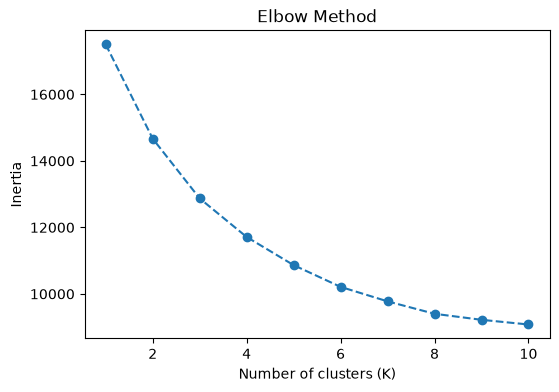

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

for k in range(1, 11):
    model = KMeans(
            n_clusters=k,           # 군집 개수 설정
            random_state=42,
            n_init=10
    )
    model.fit(X_train_scaled)

    inertia.append(model.inertia_)  # K별 결과 누적 : 군집 내 거리 제곱합

# Elbow 그래프 시각화
plt.figure(figsize=(6, 4))
plt.plot(range(1, 11), inertia, marker='o', linestyle='--')
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

**Q2. 모델 학습**

최적의 k값을 선택하여 최종 KNN 모델을 학습시키세요.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier()



**Q3. 모델 예측**

In [ ]:
# code here

**Q4. 모델 평가**

In [ ]:
# code here

## **4. 차원 축소**

**Q1. 주성분 개수를 정하지 않은 상태로 PCA를 학습(fit)합니다.**

In [ ]:
# code here

**Q2. 주성분 비율 시각화 1**

개별 설명분산을 막대 그래프로 그립니다.

In [ ]:
# code here

**Q3. 주성분 비율 시각화 2**

누적 설명 분산을 선 그래프로 그립니다.

In [ ]:
# code here

**Q3. 주성분 3개로 PCA를 적용하여 train/test 데이터를 변환하세요.**

In [ ]:
# code here

**Q4. PC1, PC2를 사용하여 산점도를 그리고, 설비 상태(status)별로 얼마나 잘 구분되는지 확인하세요.**

In [ ]:
# code here

## **5. 모델링2**

**Q1. Elbow Method를 활용하여 최적의 K값을 찾아 봅시다.**

단, 이번에는 차원 축소 된 데이터를 활용합니다.

In [ ]:
# code here

**Q2. 모델 학습**

최적의 k값을 선택하여 최종 KNN 모델을 학습시키세요.

In [ ]:
# code here

**Q3. 모델 예측**

In [ ]:
# code here

**Q4. 모델 평가**

In [ ]:
# code here

## **6. 제출하기**

데이터 전처리 방법과 학습된 모델을 활용하여 미공개 데이터에 대해 id에 일치하는 예측 결과를 DataFrame의 "status" 컬럼에 기입하고 .csv파일로 저장하여 제출합니다.

**미공개 데이터 URL:**

https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/machine_status_submission.csv

In [ ]:
sub_data = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/machine_status_submission.csv")
sub_data.head()

,id,vibration_x,vibration_y,vibration_z,vibration_axial,noise_level,temp_bearing_1,temp_bearing_2,temp_motor,temp_gearbox,...,voltage_c,pressure_inlet,pressure_outlet,pressure_mid,rotation_speed,humidity,operating_hours,oil_quality_index,equipment_age_years,outdoor_installed
0,1,7.077,6.674,6.977,7.477,7.488,72.80,70.18,70.98,72.83,...,21.758,4.907,4.920,4.484,1386.6,56.0,2812.6,78.66,0.71,No
1,2,8.175,7.318,7.833,8.456,7.654,61.08,64.24,61.72,62.39,...,19.956,4.710,4.710,4.613,1344.0,36.7,2679.5,100.10,9.73,Yes
2,3,6.213,6.169,6.524,6.124,5.735,69.62,67.42,67.26,67.39,...,20.581,4.621,4.723,4.538,1463.5,61.0,1769.7,112.99,0.54,Yes
3,4,7.994,7.896,8.110,7.885,8.409,73.66,68.51,72.16,69.73,...,20.689,4.948,5.098,5.192,1572.9,38.8,11546.6,95.22,13.22,Yes
4,5,5.957,6.715,6.845,6.685,6.889,74.41,74.26,75.36,74.76,...,23.210,4.728,4.977,4.568,1373.0,45.0,2676.2,93.44,0.98,No


In [ ]:
# code here